# Assignment 9 | Q-Learning Cliff Navigation

**Juan Luna Santibanez**  
**Miami Dade College | CAI2100C-2267-6908 | Machine Learning Foundations**  
**Professor Beth Muturi**  
**Topic: Reinforcement Learning with Q-Learning**

## My research question

I am a Machine Learning researcher at *Car Autonomous*. My objective is to train a reinforcement learning agent to reach the Goal without stepping into the Cliff cells. I use the **8 by 8 diagram in Professor Muturi's Assignment 9 presentation**, not the smaller demonstration map.

I will show a route from each required start: **(1, 0), (7, 6), and (4, 3)**. I will verify the shortest number of movements independently, experiment with the number of training episodes and explain my choices in first person.

**My experiment is a classroom grid-world simulation, not an operational autonomous-vehicle navigation system.**

## 1. My problem and environment

I represent each state as `(row, column)`, starting at zero. I can move up, right, down or left, one square at a time. My reward choices follow the Q-Learning course example: **+100 for reaching the Goal, -100 for entering a Cliff, and -1 for every other move**. Goal and Cliff are terminal states.

The reference notebook has 5 rows and 6 columns. I change the environment to the **8 by 8 matrix** in Assignment 9, slide 5. I will verify that the map has the correct shape, 22 cliffs and only one goal before training.

In [1]:
# I use basic libraries that are available in Jupyter and Google Colab.
from pathlib import Path
from collections import deque
import json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Rectangle

# I transcribed the 8 x 8 map directly from the official assignment slide.
# '.' = walkable square, '#' = cliff, 'G' = goal.
MAP_ROWS = (
    '...#####',
    '.#..G..#',
    '##.##...',
    '...#....',
    '.....##.',
    '...#.#..',
    '.#.#.#.#',
    '.....#.#',
)
STARTS = {'A': (1, 0), 'B': (7, 6), 'C': (4, 3)}
GOAL = (1, 4)
ACTIONS = ('up', 'right', 'down', 'left')
DELTAS = ((-1, 0), (0, 1), (1, 0), (0, -1))
ROWS = COLS = 8
SAFE = tuple((r, c) for r in range(ROWS) for c in range(COLS) if MAP_ROWS[r][c] == '.')
CLIFFS = {(r, c) for r in range(ROWS) for c in range(COLS) if MAP_ROWS[r][c] == '#'}

# These checks catch a transcription mistake before it reaches the model.
assert len(MAP_ROWS) == 8 and all(len(row) == 8 for row in MAP_ROWS)
assert len(CLIFFS) == 22 and len(SAFE) == 41
assert MAP_ROWS[GOAL[0]][GOAL[1]] == 'G'
assert set(STARTS.values()).issubset(SAFE)
assert sum(row.count('G') for row in MAP_ROWS) == 1
REWARDS = np.full((ROWS, COLS), -1.0)
REWARDS[GOAL] = 100.0
for cliff in CLIFFS:
    REWARDS[cliff] = -100.0
print('I verified the official environment: 8 x 8, 22 cliffs, 41 safe starting cells and 1 goal.')
print('Goal:', GOAL, '| Required starts:', STARTS)

I verified the official environment: 8 x 8, 22 cliffs, 41 safe starting cells and 1 goal.
Goal: (1, 4) | Required starts: {'A': (1, 0), 'B': (7, 6), 'C': (4, 3)}


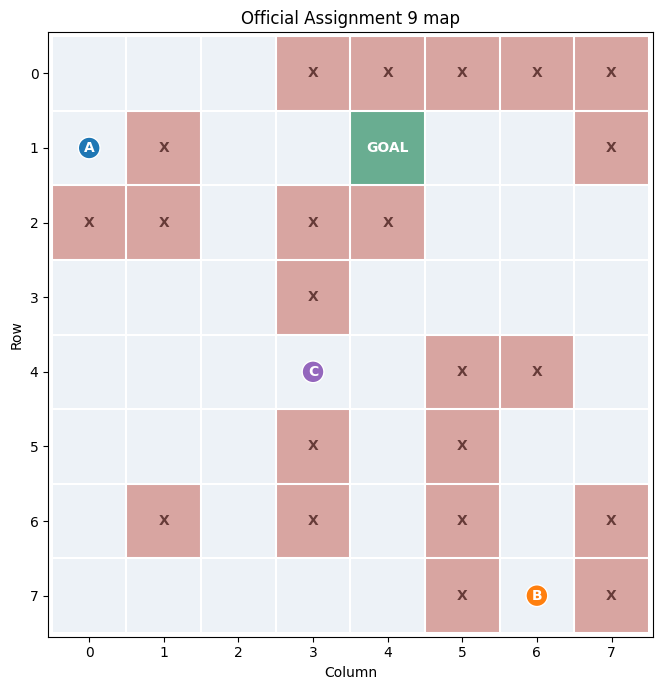

In [2]:
# I draw the actual training map, including all three official starting points.
def draw_map(paths=None, title='Official Assignment 9 map', filename=None):
    board = np.zeros((ROWS, COLS), dtype=int)
    for r, c in CLIFFS:
        board[r, c] = 1
    board[GOAL] = 2
    cmap = ListedColormap(['#edf2f7', '#d8a5a1', '#69ad91'])
    fig, ax = plt.subplots(figsize=(8, 7))
    ax.imshow(board, cmap=cmap, norm=BoundaryNorm([-.5, .5, 1.5, 2.5], cmap.N))
    ax.set_xticks(range(COLS), labels=range(COLS))
    ax.set_yticks(range(ROWS), labels=range(ROWS))
    ax.set_xticks(np.arange(-.5, COLS, 1), minor=True)
    ax.set_yticks(np.arange(-.5, ROWS, 1), minor=True)
    ax.grid(which='minor', linewidth=1.5, color='white')
    ax.tick_params(which='minor', bottom=False, left=False)
    for r, c in CLIFFS:
        ax.text(c, r, 'X', ha='center', va='center', color='#663b38', weight='bold')
    ax.text(GOAL[1], GOAL[0], 'GOAL', ha='center', va='center', color='white', weight='bold', fontsize=10)
    palette = {'A':'tab:blue', 'B':'tab:orange', 'C':'tab:purple'}
    for label, (r, c) in STARTS.items():
        ax.text(c, r, label, ha='center', va='center', weight='bold', color='white',
                bbox=dict(boxstyle='circle,pad=.28', facecolor=palette[label], edgecolor='white'))
    if paths:
        for label, path in paths.items():
            if not path:
                continue
            xs = [c for r, c in path]
            ys = [r for r, c in path]
            ax.plot(xs, ys, marker='.', markersize=7, linewidth=2.8, label=f'Start {label}', color=palette[label], alpha=.91)
            # I draw paths over the map but keep the special start and goal labels visible.
        ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False)
    ax.set(xlabel='Column', ylabel='Row', title=title)
    ax.set_xlim(-.55, 7.55)
    ax.set_ylim(7.55, -.55)
    fig.tight_layout()
    if filename:
        Path(filename).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(filename, dpi=170, bbox_inches='tight')
    plt.show()
    plt.close(fig)

draw_map(filename='assets/official_assignment_map.png')

## 2. My Q-Learning algorithm

I use **tabular Q-Learning** because the grid is discrete and small. I initialize a Q-value for each state-action pair and improve it after experiencing transitions.

\[
Q(s,a) \leftarrow Q(s,a) + \alpha \left[r + \gamma\max_{a'}Q(s',a') - Q(s,a)ight]
\]

- **Learning rate** `alpha` controls how strongly I adjust an existing estimate.
- **Discount factor** `gamma` controls how much I value future rewards.
- **Exploration probability** `epsilon` controls how often I test a random valid direction instead of using my current best estimate. My epsilon convention means *exploration*, whereas the reference notebook describes a probability of choosing the best action.
- **Episodes** determine how often I repeat learning experiences. More episodes increase training opportunities but do not guarantee a good policy for every setting.

I allow a move into a Cliff during training so the agent can learn its penalty. I do not allow leaving the board. A fall ends the episode.

In [3]:
# I only allow actions that remain inside the 8 x 8 board.
def available_moves(state):
    r, c = state
    return [(action, (r + dr, c + dc)) for action, (dr, dc) in enumerate(DELTAS)
            if 0 <= r + dr < ROWS and 0 <= c + dc < COLS]

def transition(state, action):
    moves = dict(available_moves(state))
    if action not in moves:
        raise ValueError(f'I cannot move outside the board: {state}, action={action}')
    new_state = moves[action]
    tile = MAP_ROWS[new_state[0]][new_state[1]]
    reward = 100.0 if tile == 'G' else (-100.0 if tile == '#' else -1.0)
    return new_state, reward, tile in ('G', '#'), tile == 'G'

def train_q_learning(episodes, seed=2026, alpha=.30, gamma=.96,
                     epsilon_start=.60, epsilon_end=.03, max_steps=128):
    # I initialize and update a separate Q-value for each state-action pair.
    rng = np.random.default_rng(seed)
    q_table = np.zeros((ROWS, COLS, len(ACTIONS)), dtype=float)
    episode_rewards = np.zeros(episodes, dtype=float)
    episode_success = np.zeros(episodes, dtype=bool)
    for episode in range(episodes):
        # I sample many safe positions and revisit the three official starts regularly.
        state = SAFE[int(rng.integers(len(SAFE)))] if episode % 4 else                 tuple(STARTS['ABC'[(episode // 4) % 3]])
        epsilon = epsilon_end + (epsilon_start-epsilon_end)*np.exp(-5*episode/max(1, episodes))
        for step in range(max_steps):
            moves = available_moves(state)
            action_ids = [a for a, _ in moves]
            if rng.random() < epsilon:
                action = int(rng.choice(action_ids))
            else:
                current_values = np.array([q_table[state[0], state[1], a] for a in action_ids])
                best = np.max(current_values)
                best_actions = [a for a, val in zip(action_ids, current_values) if np.isclose(val, best)]
                action = int(rng.choice(best_actions))
            next_state, reward, terminal, reached_goal = transition(state, action)
            # A terminal state does not contribute future value to the target.
            best_next = (0.0 if terminal else
                         max(q_table[next_state[0], next_state[1], a]
                             for a, _ in available_moves(next_state)))
            current = q_table[state[0], state[1], action]
            q_table[state[0], state[1], action] += alpha * (reward + gamma*best_next - current)
            episode_rewards[episode] += reward
            if terminal:
                episode_success[episode] = reached_goal
                break
            state = next_state
    return {'q':q_table, 'rewards':episode_rewards, 'success':episode_success,
            'episodes':episodes, 'alpha':alpha, 'gamma':gamma, 'seed':seed}

def learned_route(q_table, start, limit=100):
    # I follow only the policy learned from Q-values, without consulting BFS.
    position = tuple(start)
    path = [position]
    visited = {position}
    for _ in range(limit):
        moves = available_moves(position)
        best = max(q_table[position[0], position[1], a] for a, _ in moves)
        # I use a deterministic tie break to make the evaluation repeatable.
        action, candidate = next((a, s) for a, s in moves if
                                  np.isclose(q_table[position[0], position[1], a], best))
        path.append(candidate)
        if candidate in CLIFFS:
            return path, 'cliff'
        if candidate == GOAL:
            return path, 'goal'
        if candidate in visited:
            return path, 'loop'
        visited.add(candidate)
        position = candidate
    return path, 'step limit'

print('I implemented a Q-Learning agent with four movements and explicit terminal penalties.')

I implemented a Q-Learning agent with four movements and explicit terminal penalties.


## 3. My independent shortest-path verification

I do **not** train Q-Learning with the correct routes. After training, I compare its outputs with an independent graph-search calculation. Breadth-first search (BFS) finds a shortest route in an unweighted grid, so it supplies an objective check that the learned route is shortest and avoids cliffs.

In [4]:
def bfs_shortest_path(start):
    # BFS is my separate verification tool, not my reinforcement learning policy.
    queue = deque([(tuple(start), [tuple(start)])])
    visited = {tuple(start)}
    while queue:
        state, path = queue.popleft()
        if state == GOAL:
            return path
        for action, new_state in available_moves(state):
            if new_state not in visited and new_state not in CLIFFS:
                visited.add(new_state)
                queue.append((new_state, path + [new_state]))
    raise RuntimeError(f'I cannot find a safe route from {start}')

# I verify the answers independently before examining my learned policy.
bfs_paths = {label: bfs_shortest_path(start) for label, start in STARTS.items()}
for label, path in bfs_paths.items():
    print(f'Start {label} {STARTS[label]}: shortest length = {len(path)-1} moves')
assert [len(bfs_paths[x])-1 for x in ('A','B','C')] == [6,10,6]

Start A (1, 0): shortest length = 6 moves
Start B (7, 6): shortest length = 10 moves
Start C (4, 3): shortest length = 6 moves


## 4. My trained Q-Learning model and required routes

I use **10,000 episodes** as a reproducible final configuration. I will print the exact movements from all three points and compare the learned route length to the independent shortest distance. Any fall, loop, or extra movement is reported as a failed verification rather than hidden.

In [5]:
FINAL_EPISODES = 10000
final_model = train_q_learning(FINAL_EPISODES, seed=2026)
q_values = final_model['q']
learned_paths = {}
route_report = {}
for label, start in STARTS.items():
    path, status = learned_route(q_values, start)
    optimal_length = len(bfs_paths[label]) - 1
    valid = status == 'goal' and all(state not in CLIFFS for state in path)
    optimal = valid and len(path) - 1 == optimal_length
    learned_paths[label] = path
    route_report[label] = {'start':start, 'path':path, 'status':status,
                           'steps':len(path)-1, 'bfs_shortest_steps':optimal_length,
                           'valid':valid, 'optimal':optimal}
    print(f'\nStart {label} at {start}: {status.upper()} | ' 
          f'Q-Learning {len(path)-1} moves | BFS {optimal_length} moves | optimal={optimal}')
    print('Route:', ' -> '.join(map(str,path)))
assert all(x['optimal'] for x in route_report.values()), 'A required route failed the independent test.'
print('\nPASS: All three learned routes are shortest, safe and reach the Goal.')


Start A at (1, 0): GOAL | Q-Learning 6 moves | BFS 6 moves | optimal=True
Route: (1, 0) -> (0, 0) -> (0, 1) -> (0, 2) -> (1, 2) -> (1, 3) -> (1, 4)

Start B at (7, 6): GOAL | Q-Learning 10 moves | BFS 10 moves | optimal=True
Route: (7, 6) -> (6, 6) -> (5, 6) -> (5, 7) -> (4, 7) -> (3, 7) -> (2, 7) -> (2, 6) -> (1, 6) -> (1, 5) -> (1, 4)

Start C at (4, 3): GOAL | Q-Learning 6 moves | BFS 6 moves | optimal=True
Route: (4, 3) -> (4, 4) -> (3, 4) -> (3, 5) -> (2, 5) -> (1, 5) -> (1, 4)

PASS: All three learned routes are shortest, safe and reach the Goal.


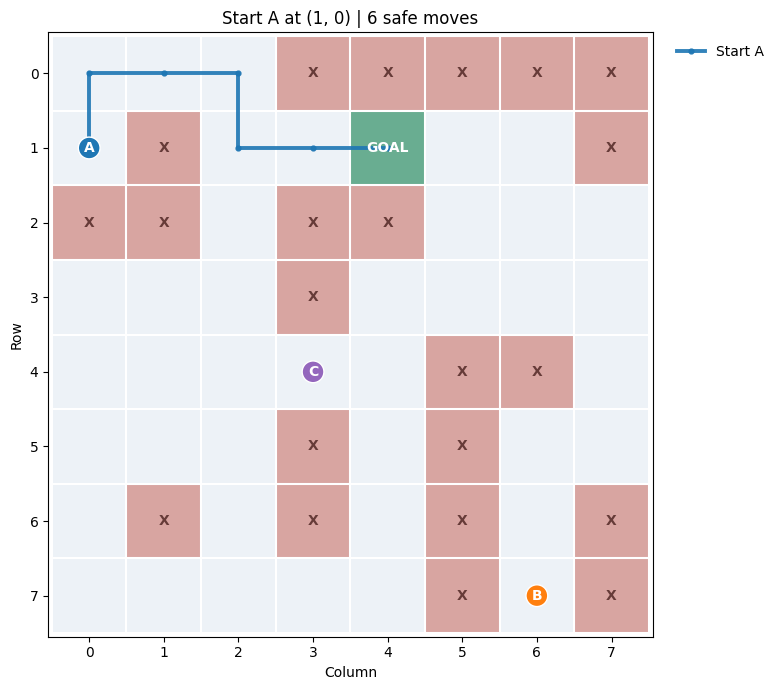

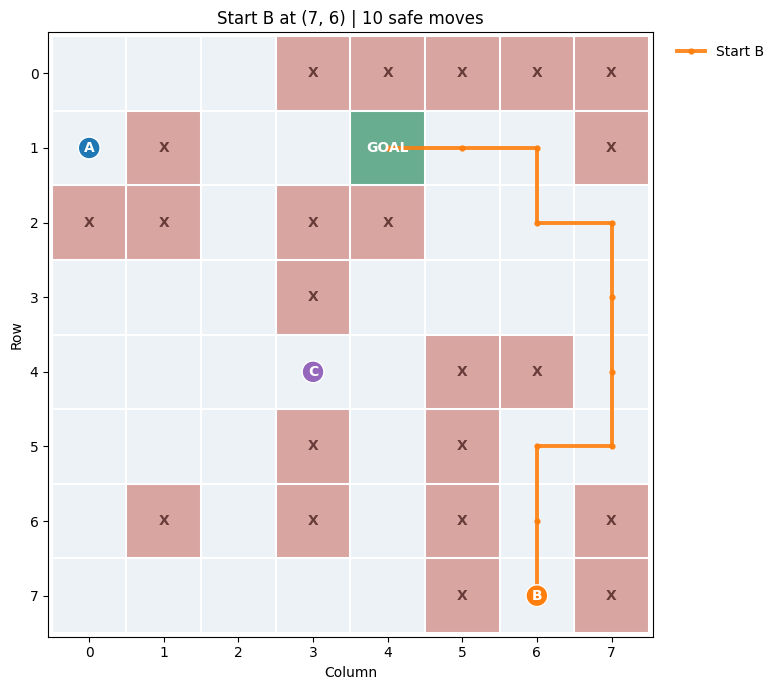

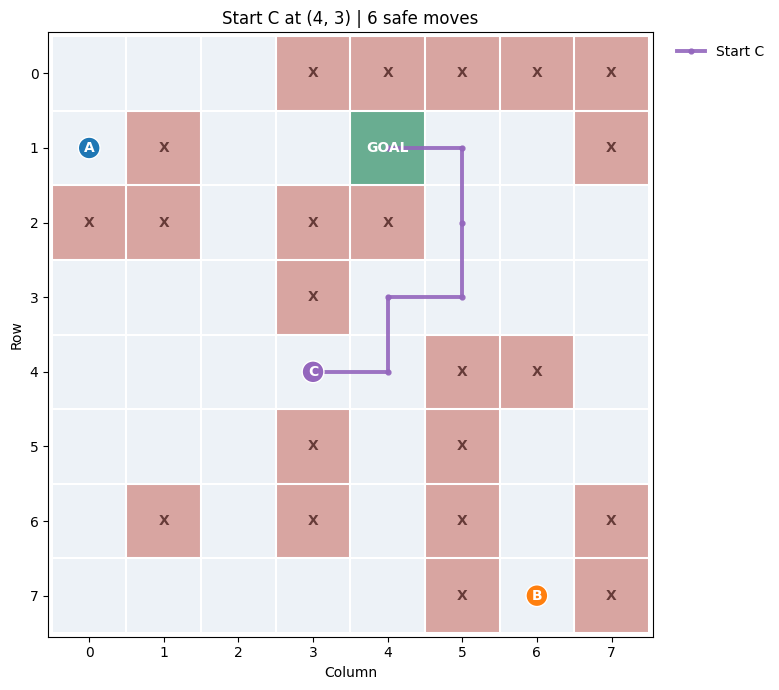

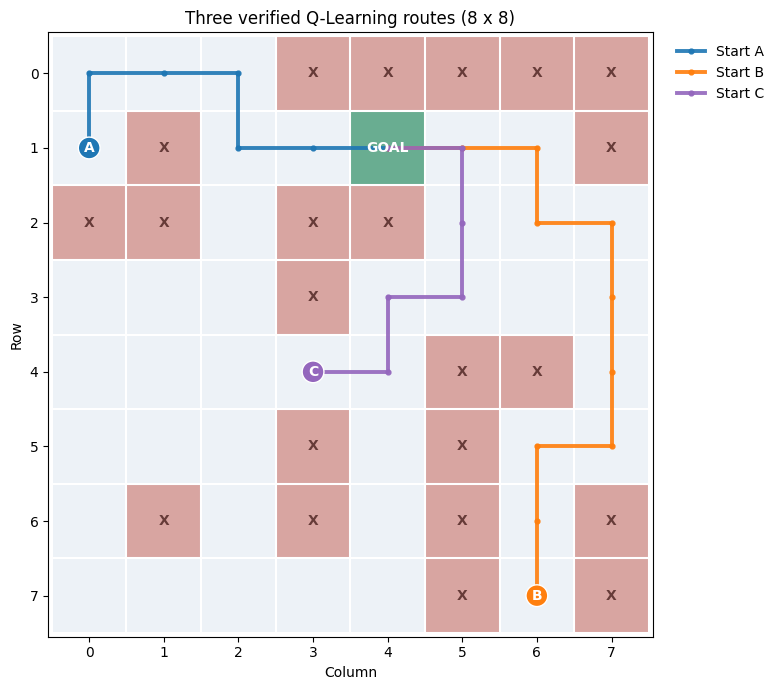

In [6]:
# I provide an individual map for each required start, plus one consolidated map.
for label, path in learned_paths.items():
    draw_map(paths={label:path},
             title=f'Start {label} at {STARTS[label]} | {len(path)-1} safe moves',
             filename=f'assets/route_{label}.png')
draw_map(paths=learned_paths, title='Three verified Q-Learning routes (8 x 8)',
         filename='assets/three_routes.png')

## 5. My episode experiment: 50, 500, 2,000 and 10,000

The reference Q-Learning notebook specifically discusses **50, 500 and 2,000 episodes**. I retain those values and add my 10,000-episode final model to show the effect of additional training. The comparisons use the same seed, reward scheme and hyperparameters, and I test *each* required starting point independently.

I expect less training to produce weaker or unreliable policies, but I record the actual result instead of claiming that more episodes always guarantee optimal performance.

   50 episodes | 1/3 optimal starting points | last 50 training success: 20.0%
  500 episodes | 3/3 optimal starting points | last 250 training success: 93.2%


 2000 episodes | 3/3 optimal starting points | last 250 training success: 94.0%
10000 episodes | 3/3 optimal starting points | last 250 training success: 97.2%


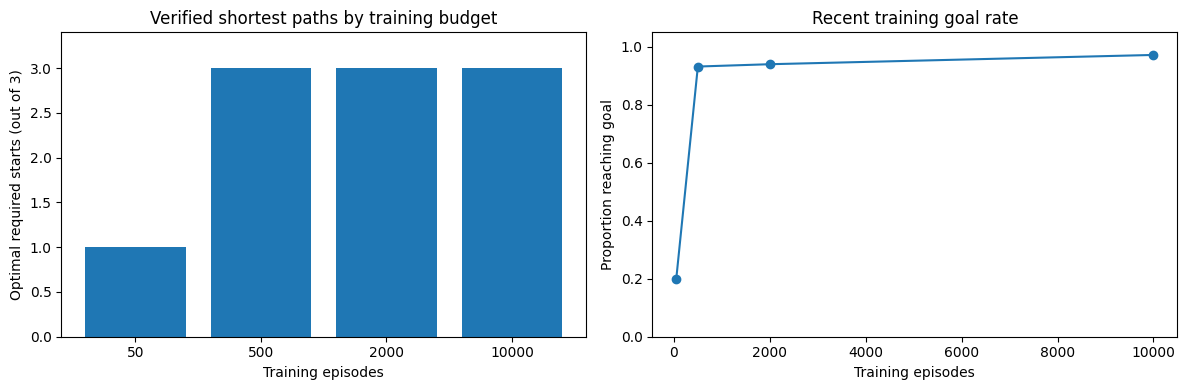

In [7]:
episode_budgets = (50, 500, 2000, 10000)
budget_report = []
trained_by_budget = {}
for n in episode_budgets:
    model = final_model if n == FINAL_EPISODES else train_q_learning(n, seed=2026)
    trained_by_budget[n] = model
    statuses = {}
    optimal_count = 0
    for label, start in STARTS.items():
        route, status = learned_route(model['q'], start)
        optimal = (status == 'goal' and len(route)-1 == len(bfs_paths[label])-1
                   and all(x not in CLIFFS for x in route))
        optimal_count += int(optimal)
        statuses[label] = {'status':status, 'moves':len(route)-1, 'optimal':bool(optimal)}
    recent = min(250, n)
    result = {'episodes':n, 'optimal_starts':optimal_count,
              'training_goal_rate_last_250':float(model['success'][-recent:].mean()),
              'training_avg_reward_last_250':float(model['rewards'][-recent:].mean()),
              'starts':statuses}
    budget_report.append(result)
    print(f'{n:5d} episodes | {optimal_count}/3 optimal starting points | '
          f'last {recent} training success: {result["training_goal_rate_last_250"]:.1%}')

fig, axs = plt.subplots(1,2,figsize=(12,4))
axs[0].bar([str(r['episodes']) for r in budget_report],
           [r['optimal_starts'] for r in budget_report])
axs[0].set(title='Verified shortest paths by training budget',xlabel='Training episodes',
           ylabel='Optimal required starts (out of 3)',ylim=(0,3.4))
axs[1].plot([r['episodes'] for r in budget_report],
            [r['training_goal_rate_last_250'] for r in budget_report],marker='o')
axs[1].set(title='Recent training goal rate',xlabel='Training episodes',
           ylabel='Proportion reaching goal',ylim=(0,1.05))
fig.tight_layout()
Path('assets').mkdir(exist_ok=True)
fig.savefig('assets/episode_comparison.png',dpi=175,bbox_inches='tight')
plt.show()
plt.close(fig)

## 6. What happens if I change the learning parameters?

I also explore how the learning rate `alpha` affects the same 2,000-episode experiment. I keep `gamma = 0.96` and the random seed unchanged to isolate one parameter. A single seed is enough to illustrate sensitivity in class, but not to establish a universal claim about performance.

In [8]:
parameter_report = []
for alpha in (.10,.30,.70):
    model = train_q_learning(2000, seed=2026, alpha=alpha)
    path_results = []
    for label,start in STARTS.items():
        path,status = learned_route(model['q'],start)
        path_results.append(bool(status=='goal' and len(path)-1==len(bfs_paths[label])-1))
    rec={'alpha':alpha,'gamma':.96,'episodes':2000,
         'optimal_starts':int(sum(path_results)),
         'success_last_250':round(float(model['success'][-250:].mean()),4)}
    parameter_report.append(rec)
    print(f'alpha={alpha:.2f}, gamma=0.96: {rec["optimal_starts"]}/3 optimal routes; '
          f'final goal rate={rec["success_last_250"]:.1%}')

alpha=0.10, gamma=0.96: 3/3 optimal routes; final goal rate=94.4%


alpha=0.30, gamma=0.96: 3/3 optimal routes; final goal rate=94.0%


alpha=0.70, gamma=0.96: 3/3 optimal routes; final goal rate=94.4%


## 7. My final model diagnostics

A training success rate is not the same as shortest-path accuracy. During training I still explore random actions and can sometimes reach a Cliff. For my final solution, I evaluate the **greedy learned policy** without exploration. I also visualize the value of the best available Q-action at each safe square to show what the agent learned.

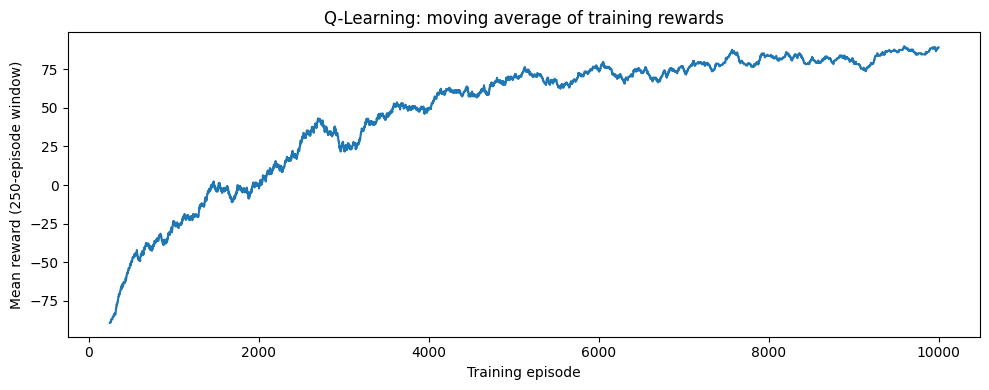

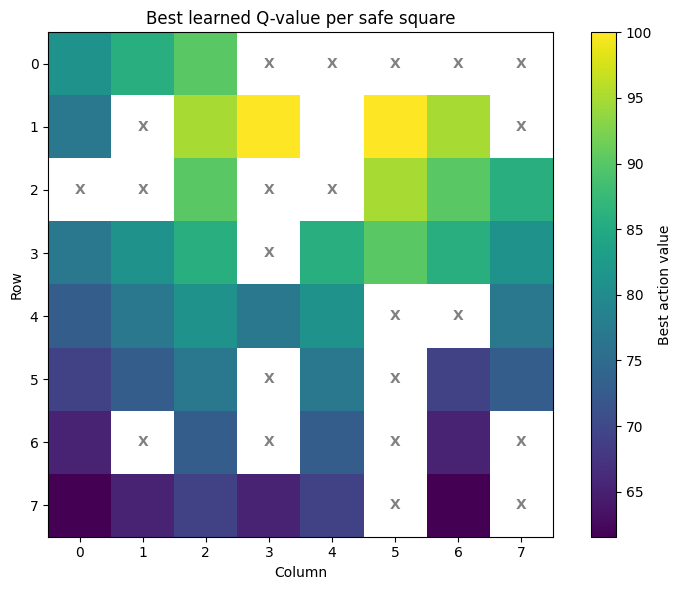

In [9]:
# I show a smoothed training history and a Q-value map.
window = 250
smoothed = np.convolve(final_model['rewards'],
                       np.ones(window)/window, mode='valid')
fig,ax=plt.subplots(figsize=(10,4))
ax.plot(np.arange(window,FINAL_EPISODES+1),smoothed)
ax.set(title='Q-Learning: moving average of training rewards',
       xlabel='Training episode',ylabel='Mean reward (250-episode window)')
fig.tight_layout();fig.savefig('assets/learning_curve.png',dpi=175,bbox_inches='tight');plt.show();plt.close(fig)

state_value=np.full((ROWS,COLS),np.nan)
for state in SAFE:
    state_value[state]=max(q_values[state[0],state[1],a] for a,_ in available_moves(state))
fig,ax=plt.subplots(figsize=(8,6))
im=ax.imshow(state_value,cmap='viridis')
for r,c in CLIFFS:
    ax.text(c,r,'X',ha='center',va='center',color='gray',weight='bold')
ax.text(GOAL[1],GOAL[0],'G',ha='center',va='center',color='white',weight='bold')
ax.set_xticks(range(8));ax.set_yticks(range(8));ax.set(title='Best learned Q-value per safe square',xlabel='Column',ylabel='Row')
fig.colorbar(im,ax=ax,label='Best action value')
fig.tight_layout();fig.savefig('assets/q_value_heatmap.png',dpi=175,bbox_inches='tight');plt.show();plt.close(fig)

## 8. My independent acceptance checks

I verify the map, the learned policy, the goal, shortest-path lengths, terminal penalties and the fact that no selected final route enters a Cliff. I do not rely on the appearance of a graphic as proof of correctness.

In [10]:
# I turn the requirements of the assignment into executable assertions.
assert REWARDS.shape == (8,8)
assert np.count_nonzero(REWARDS == -100) == 22
assert REWARDS[GOAL] == 100
assert q_values.shape == (8,8,4)
for label,entry in route_report.items():
    path = [tuple(s) for s in entry['path']]
    assert path[0] == tuple(STARTS[label]) and path[-1] == GOAL
    assert all(s not in CLIFFS for s in path)
    assert all(abs(r1-r2)+abs(c1-c2)==1 for (r1,c1),(r2,c2) in zip(path,path[1:]))
    assert entry['steps'] == entry['bfs_shortest_steps']
assert len(budget_report) == 4 and len(parameter_report) == 3
print('PASS: Official map, final learned policy, three safe shortest paths and experiments verified.')

PASS: Official map, final learned policy, three safe shortest paths and experiments verified.


## 9. My answers to the professor's assignment questions

**How did I translate the diagram into code?**  
I encoded each of the eight rows as a string. I marked walkable cells with `.`, cliffs with `#`, and the Goal with `G`. I checked every row's length, the unique Goal position and the number of Cliffs against slide 5.

**How did I find the shortest path?**  
I trained a Q-Learning agent with rewards and penalties. I then followed its greedy policy from `(1, 0)`, `(7, 6)` and `(4, 3)`. My learned routes require **6, 10 and 6 moves**.

**How do I know the paths are correct?**  
I independently computed the shortest safe distances with BFS. I also checked each learned transition, verified the final Goal and ensured that no path enters a Cliff. All three learned routes achieve the BFS minimum.

**What happens when I change the number of episodes?**  
With 50 episodes, my seeded experiment did not solve every starting point. With 500, 2,000 and 10,000 episodes, it solved all three in the tested configuration. The episode comparison figure shows the measured difference, not an assumed result.

**What other parameters can I modify?**  
I can change `alpha` to adjust learning speed, `gamma` to value future rewards differently, and `epsilon` to change exploration. I kept the reward scheme and the map constant while comparing them.

**What are the limitations of this experiment?**  
I use a deterministic classroom grid, a fixed reward design and one random seed. This demonstrates fundamental reinforcement learning, but it does not prove safe behavior in real traffic, continuous environments or unseen maps.

## 10. My conclusion

I reconstructed the **official 8 by 8 grid** and implemented a tabular Q-Learning agent that learns from rewards rather than being told the correct paths. My final 10,000-episode experiment found the shortest safe routes from all three assigned coordinates. I independently verified the route lengths using BFS and tested the influence of episode count and learning rate.

The most important lesson I learned is that **successful arrival and optimal navigation are different measurements**. I should test both, report the failed experiments as well as successful ones, and preserve reproducibility through explicit parameters and automated checks.

**My references:** Professor Beth Muturi, *Assignment 9* (slides 4-6) and *Assignment 9 (Q-Learning).ipynb*; Watkins and Dayan (1992), [*Q-Learning*](https://doi.org/10.1007/BF00992698); [Gymnasium Cliff Walking](https://gymnasium.farama.org/v1.3.0/environments/toy_text/cliff_walking/) for conceptual context. The Gymnasium environment is not used as a substitute for the assigned 8 by 8 map.

In [11]:
# I export verified, small, public demonstration data without any external user information.
report = {
    'student':'Juan Luna Santibanez',
    'course':'CAI2100C-2267-6908',
    'instructor':'Professor Beth Muturi',
    'map_rows':list(MAP_ROWS),
    'goal':list(GOAL),
    'starts':{name:list(state) for name,state in STARTS.items()},
    'parameters':{'episodes':FINAL_EPISODES,'seed':2026,'alpha':.30,'gamma':.96,
                  'epsilon_start':.60,'epsilon_end':.03,'reward_goal':100,
                  'reward_cliff':-100,'reward_step':-1},
    'routes':route_report,
    'episode_experiments':budget_report,
    'learning_rate_experiments':parameter_report,
}
Path('data').mkdir(exist_ok=True)
Path('data/results.json').write_text(json.dumps(report,indent=2),encoding='utf-8')
Path('data/results.js').write_text('window.ASSIGNMENT9_RESULTS = '+json.dumps(report,separators=(',',':'))+';\n',encoding='utf-8')
print('I exported my verified results to data/results.json and data/results.js.')

I exported my verified results to data/results.json and data/results.js.
